## C1 - WEEK 2

- Adrià Cantarero Carreras  (1809773@uab.cat)
- Ivan Martin Campoy (1673246@uab.cat)
- Irene Pumares Benaiges (1810704@uab.cat)
- Lavish Ramchandani (1691238@uab.cat)

In [23]:
import sys
sys.path.append("..")  # repo root, for utils/
#needed libraries

import os
import re
import cv2
import pickle
import numpy as np
from functools import partial
from tqdm.auto import tqdm
import time
import matplotlib.pyplot as plt

## TASK 1: Implement 3D / 2D and block and hierarchical histograms

In [24]:
#database and qsd1 and qsd2 paths

bbdd_path = "./data/BBDD"
qsd2_path = "./data/qsd2_w1"
qsd1_path = "./data/qsd1_w1"

COLOR_SPACES = {
    "GRAY": cv2.COLOR_BGR2GRAY,
    "RGB":  cv2.COLOR_BGR2RGB,
    "HSV":  cv2.COLOR_BGR2HSV,
    "LAB":  cv2.COLOR_BGR2LAB,
    "YCRCB": cv2.COLOR_BGR2YCrCb,
}
#----------------------------------------------------------------------------------

CHANNEL_RANGES = {
    "GRAY":  [(0, 256)],
    "RGB":   [(0, 256)] * 3,
    "HSV":   [(0, 180), (0, 256), (0, 256)],
    "LAB":   [(0, 256)] * 3,
    "YCRCB": [(0, 256)] * 3,
}

def read_image(img_path):
    image = cv2.imread(img_path)
    if image is None:
        raise IOError(f"Could not read {img_path}")   #skipping it would shift every index after it and break the ground truth
    return image

bbdd_descriptors = []
qsd2_descriptors = []

#----------------------------------------------------------------------------------
#sort files
def return_number(string):
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', string)]

#sort bbdd files
bbdd_files = [f for f in os.listdir(bbdd_path) if f.lower().endswith(".jpg")]
bbdd_files.sort(key=return_number)

#sort qsd2 files
qsd2_files = [f for f in os.listdir(qsd2_path) if f.lower().endswith(".jpg")]
qsd2_files.sort(key=return_number)

qsd1_files = [f for f in os.listdir(qsd1_path) if f.lower().endswith(".jpg")]
qsd1_files.sort(key=return_number)

#id of an image = number in its file name (bbdd_00007.jpg -> 7)
def image_id(file_name):
    return int(re.findall(r'\d+', file_name)[-1])

bbdd_ids = np.array([image_id(f) for f in bbdd_files])
qsd2_ids = np.array([image_id(f) for f in qsd2_files])
qsd1_ids = np.array([image_id(f) for f in qsd1_files])
#----------------------------------------------------------------------------------

#load images iteratively bbdd set
bbdd_imgs = []
for file_name in bbdd_files:
    img_path = os.path.join(bbdd_path, file_name)
    image = read_image(img_path)
    bbdd_imgs.append(image)

qsd1_imgs = []
for file_name in qsd1_files:
    img_path = os.path.join(qsd1_path, file_name)
    image = read_image(img_path)
    qsd1_imgs.append(image)

##load images iteratively qsd2 set
qsd2_imgs = []
for file_name in qsd2_files:
    img_path = os.path.join(qsd2_path, file_name)
    image = read_image(img_path)
    qsd2_imgs.append(image)

In [25]:
def compute_nd_histogram(image,color_space = 'HSV', channels = (1,2), bins= 16, mask = None):
    if mask is not None:
        mask = (mask > 0).astype(np.uint8) * 255 #convert boolean mask to 0-255 just in case

    ranges = [] #ranges for the color space channels
    if color_space in COLOR_SPACES:
        converted_image = cv2.cvtColor(image, COLOR_SPACES[color_space])
        if len(converted_image.shape) == 2:
            raise ValueError("Descriptor needs 2 channels at least")

        for c in channels:
            ranges.extend(CHANNEL_RANGES[color_space][c])

    else:
        raise ValueError("Unknown color space: %s" % color_space)

    if isinstance(bins, int):
        hist_size = [bins for i in channels] #ex 16 -> (16,16)
    else:
        assert len(bins) == len(channels), "Number of bins must match number of channels"
        hist_size = bins
  
    hist = cv2.calcHist([converted_image], list(channels), mask, hist_size, ranges)
    hist = hist.flatten()

    #normalize only once
    total = np.sum(hist)
    if total > 0:
        hist = hist / total
    return hist


image = cv2.imread("./data/BBDD/bbdd_00000.jpg")
d = compute_nd_histogram(image)

In [26]:
def compute_block_histogram(image, grid=(4, 4), color_space='HSV', channels=(1, 2), bins=16, mask=None):
    # 1. block boundaries
    rows, cols = grid
    height, width = image.shape[:2]
    y_cuts  = np.linspace(0, height, rows + 1, dtype=int)
    x_cuts  = np.linspace(0, width, cols + 1, dtype=int)
    block_histograms = []

    # 2. loop over blocks: slice image (and mask), call compute_nd_histogram
    for r in range(rows):
        for c in range(cols):
            y_start, y_end = y_cuts[r], y_cuts[r+1]
            x_start, x_end = x_cuts[c], x_cuts[c+1]
            block_img = image[y_start:y_end, x_start:x_end]
            block_mask = None
            if mask is not None:
                block_mask = mask[y_start:y_end, x_start:x_end]
        
            hist = compute_nd_histogram(block_img, color_space, channels, bins, block_mask)
            block_histograms.append(hist)

    # 3. concatenate (and decide the normalization)
    descriptor = np.concatenate(block_histograms)
    total = np.sum(descriptor)
    if total > 0:
        descriptor = descriptor / total
    return descriptor

image = cv2.imread("./data/BBDD/bbdd_00000.jpg")
d = compute_block_histogram(image)


In [27]:
def compute_pyramid_histogram(image, levels=((1, 1), (2, 2), (4, 4)), weights=None,
                              color_space='HSV', channels=(0, 1), bins=16, mask=None):
    if weights is None:
        weights = np.ones(len(levels), dtype=np.float32) #default to equal weights if none passed
    else:
        weights = np.asarray(weights, dtype=np.float32) #convert weights to numpy array just in case

    assert len(weights) == len(levels), "len(weights) must match len(levels)" #make sure weight count matches level count

    if color_space in COLOR_SPACES:
        converted_image = cv2.cvtColor(image, COLOR_SPACES[color_space]) #convert color space once here to save time
    else:
        raise ValueError(f"Unknown color space: {color_space}") #throw error if color space isnt valid

    n_channels = len(channels) #count active channels
    hist_size = (bins,) * n_channels if isinstance(bins, int) else tuple(bins) #build tuple for bin counts
    bins_per_block = np.prod(hist_size) #total bins in a single block
    
    total_blocks = sum(r * c for r, c in levels) #sum all blocks across every level
    descriptor = np.empty(total_blocks * bins_per_block, dtype=np.float32) #preallocate full output vector upfront

    ranges = []
    for c in channels:
        ranges.extend(CHANNEL_RANGES[color_space][c]) #grab min max range for each channel

    if mask is not None:
        mask = (mask > 0).astype(np.uint8) * 255 #make sure mask is uint8 for opencv

    height, width = converted_image.shape[:2] #grab image dimensions
    offset = 0 #pointer to fill the descriptor array

    for (rows, cols), w in zip(levels, weights):
        y_cuts = np.linspace(0, height, rows + 1, dtype=int) #calculate vertical cuts for grid
        x_cuts = np.linspace(0, width, cols + 1, dtype=int) #calculate horizontal cuts for grid

        for r in range(rows):
            for c in range(cols):
                y0, y1 = y_cuts[r], y_cuts[r+1] #crop boundaries for y
                x0, x1 = x_cuts[c], x_cuts[c+1] #crop boundaries for x
                
                block_img = converted_image[y0:y1, x0:x1] #slice current block from image
                block_mask = mask[y0:y1, x0:x1] if mask is not None else None #slice matching mask area if present

                hist = cv2.calcHist([block_img], list(channels), block_mask, hist_size, ranges).ravel() #calc block hist
                
                block_total = hist.sum() #sum up all bins in block
                if block_total > 0:
                    hist /= block_total #normalize block so it sums to 1

                next_offset = offset + bins_per_block #compute end slice position
                descriptor[offset:next_offset] = hist * w #store weighted block directly in place
                offset = next_offset #slide pointer forward for next block

    total = descriptor.sum() #sum entire combined descriptor
    if total > 0:
        descriptor /= total #final l1 normalization on whole vector

    return descriptor

## Task2: Test query system using query set QSD1-W2 development, evaluate retrieval results (use your best performing descriptor).
Compare results against the best descriptor/distance in W1 (the dev set is the same)

In [28]:
eps = 1e-10  # small value to avoid division by zero


def euclidean_distance(x, y):
    return np.sqrt(np.sum((x - y) ** 2, axis=-1))

def L1_distance(x, y):
    return np.sum(np.abs(x - y), axis=-1)

def chi_squared_distance(x, y):
    return 0.5 * np.sum(((x - y) ** 2) / (x + y + eps), axis=-1)

def jensen_shannon_distance(x, y):
    m = 0.5 * (x + y)
    kl_x = np.sum(x * np.log((x + eps) / (m + eps)), axis=-1)
    kl_y = np.sum(y * np.log((y + eps) / (m + eps)), axis=-1)
    return np.sqrt(np.clip(0.5 * (kl_x + kl_y), 0, None))

#all the measures below are written as distances (smaller = more similar) because the retrieval step will rank every measure 
#with the same rule (sort ascending and take the first k)

def histogram_intersection_distance(x, y):
    return 1.0 - np.sum(np.minimum(x, y), axis=-1)

def hellinger_distance(x, y):
    return (1.0 / np.sqrt(2.0)) * np.sqrt(np.sum((np.sqrt(np.clip(x, 0, None)) - np.sqrt(np.clip(y, 0, None))) ** 2, axis=-1))

def cosine_distance(x, y):
    return 1.0 - np.sum(x * y, axis=-1) / (np.linalg.norm(x, axis=-1) * np.linalg.norm(y, axis=-1) + eps)

def correlation_distance(x, y):
    xc = x - np.mean(x, axis=-1, keepdims=True)
    yc = y - np.mean(y, axis=-1, keepdims=True)
    return 1.0 - np.sum(xc * yc, axis=-1) / (np.linalg.norm(xc, axis=-1) * np.linalg.norm(yc, axis=-1) + eps)

MEASURES = {
    "euclidean":      euclidean_distance,
    "L1":             L1_distance,
    "chi2":           chi_squared_distance,
    "intersection":   histogram_intersection_distance,
    "hellinger":      hellinger_distance,
    "cosine":         cosine_distance,
    "correlation":    correlation_distance,
    "jensen_shannon": jensen_shannon_distance,
}

# import ml_metrics as metrics #Couldn't install it so I copied the code from the git

import numpy as np

#code from https://github.com/benhamner/Metrics/blob/master/Python/ml_metrics/custom/kdd_average_precision.py
def kdd_apk(actual, predicted, k=10):
    """
    Computes the average precision at k for Track 1 of the 2012 KDD Cup.

    This modified version uses the number of actual clicks as the denominator,
    regardless of k.

    This function computes the average prescision at k between two lists of
    items.

    Parameters
    ----------
    actual : list
             A list of elements that are to be predicted (order doesn't matter)
    predicted : list
                A list of predicted elements (order does matter)
    k : int, optional
        The maximum number of predicted elements

    Returns
    -------
    score : double
            The average precision at k over the input lists

    """
    if len(predicted)>k:
        predicted = predicted[:k]

    score = 0.0
    num_hits = 0.0

    for i,p in enumerate(predicted):
        if p in actual and p not in predicted[:i]: #p not in predicted[:i] is to avoid no extra marks for repeating
            num_hits += 1.0
            score += num_hits / (i+1.0)

    if not actual:
        return 0.0

    return score / len(actual)

def kdd_mapk(actual, predicted, k=10):
    """
    Computes the mean average precision at k for Track 1 of the 2012 KDD Cup.

    This modified version uses the number of actual clicks as the denominator,
    regardless of k.

    This function computes the mean average prescision at k between two lists
    of lists of items.

    Parameters
    ----------
    actual : list
             A list of lists of elements that are to be predicted 
             (order doesn't matter in the lists)
    predicted : list
                A list of lists of predicted elements
                (order matters in the lists)
    k : int, optional
        The maximum number of predicted elements

    Returns
    -------
    score : double
            The mean average precision at k over the input lists

    """
    return np.mean([kdd_apk(a,p,k) for a,p in zip(actual, predicted)])


#apk is like the average precision of hits at k items
#but mapk looks in the entire dataset

import pandas as pd
from IPython.display import display

gt_path = os.path.join(qsd1_path, "gt_corresps.pkl")
with open(gt_path, "rb") as f:
    gt_corresps = pickle.load(f)

num_queries = len(gt_corresps)
assert num_queries == len(qsd1_files), (
    f"GT has {num_queries} entries but QSD1 has {len(qsd1_files)} images."
)
assert len(bbdd_ids) == len(bbdd_files), "BBDD IDs do not match the database files."
actual_ids = [[int(item) for item in query_gt] for query_gt in gt_corresps]


In [29]:
def compute_descriptors(images, descriptor_fn):
    # preallocated matrix (N, D): avoids the list -> array copy that doubles peak memory
    first = np.asarray(descriptor_fn(images[0]), dtype=np.float32)
    descriptors = np.empty((len(images), first.size), dtype=np.float32)
    descriptors[0] = first
    for i in range(1, len(images)):
        descriptors[i] = descriptor_fn(images[i])
    return descriptors

from utils.extra_descriptors import retrieve_topk
def evaluate_descriptors(db_desc, query_desc, measures):
    # db_desc: (287, D) matrix from compute_descriptors on BBDD
    # query_desc: (30, D) matrix from compute_descriptors on QSD1
    # measures: dict {name: distance function}, e.g. MEASURES

    results = []
    for name, measure in measures.items():
        # 1. skip "emd" (it is not meaningful for flattened 2D/3D histograms)
        # 2. top-5 predictions for all queries -> retrieve_topk(...)
        predictions = retrieve_topk(query_desc, db_desc, bbdd_ids, measure, k=5)
        # 3. mAP@1: use only the first prediction of each query -> kdd_mapk(...)
        map1 = kdd_mapk(actual_ids, predictions, k = 1)
        # 4. mAP@5: use the five predictions -> kdd_mapk(...)
        map5 = kdd_mapk(actual_ids, predictions, k = 5)
        # 5. store a dict with distance name, MAP@1 and MAP@5
        results.append({"Distance": name, "MAP@1": map1, "MAP@5": map5})
    return results

In [30]:
import pandas as pd
from functools import partial

# 1. hyperparameters
color_spaces = ["HSV", "LAB", "YCRCB", "RGB"]
PAIRS_2D = {"HSV": (0, 1), "LAB": (1, 2), "YCRCB": (1, 2)}

bins_list = [8, 16, 32]

#configs
block_grids = [(2, 2), (4, 4), (8, 8)]
pyramid_levels = [((1, 1), (2, 2)), ((1, 1), (2, 2), (4, 4)), ((1, 1), (2, 2), (4, 4), (8, 8))]

grid_experiments = []

def pyramid_weights(scheme, n_levels):
    if scheme == "equal":
        return np.ones(n_levels) #assign equal weight (1.0) to all levels
    if scheme == "fine":
        return 2.0 ** np.arange(n_levels)  #exponential growth (1, 2, 4, etc): gives more weight to fine levels
    raise ValueError(f"Unknown weight scheme: {scheme}")

# 2. grid Search for  block descriptors
def run_grid_search(color_spaces=("HSV", "LAB", "YCRCB", "RGB"), bins_3d=(8, 16), bins_2d=(16, 32),
                    block_grids=((2, 2), (4, 4), (8, 8)),
                    pyramid_levels=(((1, 1), (2, 2)), ((1, 1), (2, 2), (4, 4)), ((1, 1), (2, 2), (4, 4), (8, 8))),
                    weight_schemes=("equal", "fine"), skip_measures=("intersection",),
                    results_path=os.path.join("results", "grid_search_w2_full.csv")):
    # needs: bbdd_imgs, qsd1_imgs, MEASURES, evaluate_descriptors, compute_block_histogram
    # intersection is skipped by default: for L1-normalized histograms it gives the same ranking as L1
    measures = {k: v for k, v in MEASURES.items() if k not in skip_measures}

    # 1. a "family" = (color space, channels, bins); its block descriptors are computed once
    #    and reused by every block grid and every pyramid of that family
    families = []
    for cs in color_spaces:
        for b in bins_3d:
            families.append((cs, (0, 1, 2), b))
        if cs in PAIRS_2D:
            for b in bins_2d:
                families.append((cs, PAIRS_2D[cs], b))
    families.sort(key=lambda f: f[2] ** len(f[1]))  # cheap families first

    # 2. resume: families already saved in the CSV are skipped (a crash does not lose the work)
    rows, done = [], set()
    if os.path.exists(results_path):
        old = pd.read_csv(results_path)
        rows, done = old.to_dict("records"), set(old["Family"])
    os.makedirs(os.path.dirname(results_path) or ".", exist_ok=True)

    grids_needed = sorted(set(block_grids) | {g for levels in pyramid_levels for g in levels})
    pbar = tqdm(families, desc="Grid search")

    for cs, channels, b in pbar:
        family = f"{cs}|{''.join(map(str, channels))}|{b}"
        if family in done:
            continue
        t0, nd = time.time(), f"{len(channels)}D"

        # 3. block descriptors of every grid (BBDD and queries with the SAME function)
        cache = {}
        for grid in grids_needed:
            pbar.set_postfix_str(f"{family} | descriptors {grid[0]}x{grid[1]}")
            fn = partial(compute_block_histogram, grid=grid, color_space=cs, channels=channels, bins=b)
            cache[grid] = (compute_descriptors(bbdd_imgs, fn), compute_descriptors(qsd1_imgs, fn))

        def evaluate(desc_type, config, grid_levels, weights_name, db, q):
            pbar.set_postfix_str(f"{family} | evaluating {config}")
            for res in evaluate_descriptors(db, q, measures):
                rows.append({"Type": desc_type, "Config": config, "Family": family, "Color Space": cs,
                            "Channels": str(channels), "Bins": b, "Grid/Levels": grid_levels,
                            "Weights": weights_name, "Dim": db.shape[1], "Distance": res["Distance"],
                            "MAP@1": res["MAP@1"], "MAP@5": res["MAP@5"]})

        # 4. blocks
        for grid in block_grids:
            evaluate("Block", f"Block {grid[0]}x{grid[1]} | {cs} {nd} | Bins: {b}", str(grid), "-", *cache[grid])

        # 5. pyramids: weighted concatenation of the cached levels (no recomputation of histograms)
        for levels in pyramid_levels:
            levels_str = "->".join(f"{g[0]}x{g[1]}" for g in levels)
            for scheme in weight_schemes:
                w = pyramid_weights(scheme, len(levels))
                parts = [float(wi / w.sum()) for wi in w]  # python floats keep float32
                db = np.hstack([p * cache[g][0] for p, g in zip(parts, levels)])
                q = np.hstack([p * cache[g][1] for p, g in zip(parts, levels)])
                evaluate("Pyramid", f"Pyramid ({levels_str}) [{scheme}] | {cs} {nd} | Bins: {b}",
                        str(levels), scheme, db, q)

        del cache  # free memory before the next family
        pd.DataFrame(rows).to_csv(results_path, index=False)  # checkpoint
        pbar.write(f"{family}: {time.time() - t0:.0f}s")

    df = pd.DataFrame(rows).sort_values(["MAP@1", "MAP@5"], ascending=False).reset_index(drop=True)
    df.to_csv(results_path, index=False)
    return df


df_grid_all = run_grid_search(
    block_grids=tuple(block_grids), 
    pyramid_levels=tuple(pyramid_levels)
)

print("\n=== TOP 10 GLOBAL CONFIGS FROM THE GRID SEARCH ===")
display(df_grid_all.head(10))

#5. Extract winner and check with week 1 winner
best_grid_winner = df_grid_all.iloc[0]

w1_best_map1 = 0.6333
w1_best_map5 = 0.6872

comparison_table = [
    {
        "Week": "Week 1 (Best Baseline)",
        "Descriptor / Method": "Global 1D CLAHE + LAB",
        "Distance Metric": "L1",
        "mAP@1 QSD1": w1_best_map1,
        "mAP@5 QSD1": w1_best_map5,
        "Gain mAP@1": "-"
    },
    {
        "Week": "Week 2 (Grid Search Winner)",
        "Descriptor / Method": best_grid_winner["Config"],
        "Distance Metric": best_grid_winner["Distance"],
        "mAP@1 QSD1": round(best_grid_winner["MAP@1"], 4),
        "mAP@5 QSD1": round(best_grid_winner["MAP@5"], 4),
        "Gain mAP@1": f"+{round(best_grid_winner['MAP@1'] - w1_best_map1, 4):.4f}"
    }
]

df_comparison_final = pd.DataFrame(comparison_table)

print("\n=== Final comparison: Best W1 VS winner of the grid search of W2 ===")
display(df_comparison_final)

Grid search: 100%|██████████| 14/14 [00:00<00:00, 172706.64it/s]


=== TOP 10 GLOBAL CONFIGS FROM THE GRID SEARCH ===


,Type,Config,Family,Color Space,Channels,Bins,Grid/Levels,Weights,Dim,Distance,MAP@1,MAP@5
0,Block,Block 8x8 | YCRCB 2D | Bins: 16,YCRCB|12|16,YCRCB,"(1, 2)",16,"(8, 8)",-,16384,chi2,0.833333,0.850000
1,Block,Block 8x8 | YCRCB 2D | Bins: 16,YCRCB|12|16,YCRCB,"(1, 2)",16,"(8, 8)",-,16384,hellinger,0.800000,0.841667
2,Block,Block 8x8 | LAB 2D | Bins: 16,LAB|12|16,LAB,"(1, 2)",16,"(8, 8)",-,16384,jensen_shannon,0.800000,0.834444
3,Block,Block 8x8 | YCRCB 2D | Bins: 16,YCRCB|12|16,YCRCB,"(1, 2)",16,"(8, 8)",-,16384,euclidean,0.800000,0.833333
4,Block,Block 8x8 | YCRCB 2D | Bins: 16,YCRCB|12|16,YCRCB,"(1, 2)",16,"(8, 8)",-,16384,L1,0.800000,0.833333
5,Block,Block 8x8 | YCRCB 2D | Bins: 16,YCRCB|12|16,YCRCB,"(1, 2)",16,"(8, 8)",-,16384,jensen_shannon,0.800000,0.833333
6,Block,Block 8x8 | RGB 3D | Bins: 16,RGB|012|16,RGB,"(0, 1, 2)",16,"(8, 8)",-,262144,chi2,0.800000,0.833333
7,Pyramid,Pyramid (1x1->2x2->4x4->8x8) [fine] | YCRCB 2D...,YCRCB|12|16,YCRCB,"(1, 2)",16,"((1, 1), (2, 2), (4, 4), (8, 8))",fine,21760,chi2,0.800000,0.827778
8,Block,Block 8x8 | LAB 2D | Bins: 16,LAB|12|16,LAB,"(1, 2)",16,"(8, 8)",-,16384,hellinger,0.800000,0.825000
9,Block,Block 8x8 | LAB 2D | Bins: 32,LAB|12|32,LAB,"(1, 2)",32,"(8, 8)",-,65536,hellinger,0.800000,0.816667



=== Final comparison: Best W1 VS winner of the grid search of W2 ===


,Week,Descriptor / Method,Distance Metric,mAP@1 QSD1,mAP@5 QSD1,Gain mAP@1
0,Week 1 (Best Baseline),Global 1D CLAHE + LAB,L1,0.6333,0.6872,-
1,Week 2 (Grid Search Winner),Block 8x8 | YCRCB 2D | Bins: 16,chi2,0.8333,0.8500,+0.2000


In [31]:

#saving path
output_dir = "results"
os.makedirs(output_dir, exist_ok=True)

#save grid search results
df_grid_all.to_csv(os.path.join(output_dir, "grid_search_results_w2.csv"), index=False)

#save W1 vs W2 comparison table
df_comparison_final.to_csv(os.path.join(output_dir, "comparison_w1_vs_w2.csv"), index=False)

print("Files saved successfully as CSV in 'results'!")

Files saved successfully as CSV in 'results'!


In [32]:
# 1. BEST performing descriptor found during Grid Search (Week 2)
best_w2_descriptor = partial(
    compute_block_histogram,
    grid=(8, 8),
    color_space='YCRCB',
    channels=(1, 2),
    bins=16
)

# 2. Extract feature descriptors for BBDD and QSD1-W2 datasets
print("Extracting descriptors for BBDD using the best W2 model...")
db_desc = compute_descriptors(bbdd_imgs, best_w2_descriptor)

print("Extracting descriptors for QSD1-W2 using the best W2 model...")
query_desc = compute_descriptors(qsd1_imgs, best_w2_descriptor)

# 3. Evaluate retrieval performance across all distance measures
results_best = evaluate_descriptors(db_desc, query_desc, MEASURES)

# 4. Display results sorted by MAP@1
df_results_best = pd.DataFrame(results_best).sort_values(by="MAP@1", ascending=False)
print("=== BEST DESCRIPTOR RESULTS IN W2 (Block 8x8 | YCrCb 2D | Bins 16) ===")
display(df_results_best)

# 5. DIRECT COMPARISON: BEST DESCRIPTOR/DISTANCE IN W1 VS BEST IN W2
w1_best_map1 = 0.6333
w1_best_map5 = 0.6872

best_w2_row = df_results_best.iloc[0]

comparison_table = [
    {
        "Week": "Week 1 (Best Baseline)",
        "Descriptor / Method": "Global 1D CLAHE + LAB",
        "Distance Metric": "L1",
        "mAP@1 QSD1": w1_best_map1,
        "mAP@5 QSD1": w1_best_map5,
        "Gain mAP@1": "-"
    },
    {
        "Week": "Week 2 (Best Proposed)",
        "Descriptor / Method": "Block 8x8 | YCRCB 2D | Bins: 16",
        "Distance Metric": best_w2_row["Distance"],
        "mAP@1 QSD1": round(best_w2_row["MAP@1"], 4),
        "mAP@5 QSD1": round(best_w2_row["MAP@5"], 4),
        "Gain mAP@1": f"+{round(best_w2_row['MAP@1'] - w1_best_map1, 4):.4f}"
    }
]

df_task2_comparison = pd.DataFrame(comparison_table)
print("\n=== TASK 2 COMPARISON: BEST W1 VS BEST W2 ===")
display(df_task2_comparison)

Extracting descriptors for BBDD using the best W2 model...
Extracting descriptors for QSD1-W2 using the best W2 model...
=== BEST DESCRIPTOR RESULTS IN W2 (Block 8x8 | YCrCb 2D | Bins 16) ===


,Distance,MAP@1,MAP@5
2,chi2,0.833333,0.850000
0,euclidean,0.800000,0.833333
1,L1,0.800000,0.833333
3,intersection,0.800000,0.833333
4,hellinger,0.800000,0.841667
7,jensen_shannon,0.800000,0.833333
5,cosine,0.766667,0.791667
6,correlation,0.766667,0.791667



=== TASK 2 COMPARISON: BEST W1 VS BEST W2 ===


,Week,Descriptor / Method,Distance Metric,mAP@1 QSD1,mAP@5 QSD1,Gain mAP@1
0,Week 1 (Best Baseline),Global 1D CLAHE + LAB,L1,0.6333,0.6872,-
1,Week 2 (Best Proposed),Block 8x8 | YCRCB 2D | Bins: 16,chi2,0.8333,0.8500,+0.2000


## Task 3: Background removal using only colour (QSD2-W2)

### 3.1. Background color model

00001.jpg
  Lab: wall (a*, b*) = [130. 135.]   L*_wall = 168.0
  rgb: wall (b, g, r) = [0.3095 0.3353 0.3571]   grey_wall = 160.0


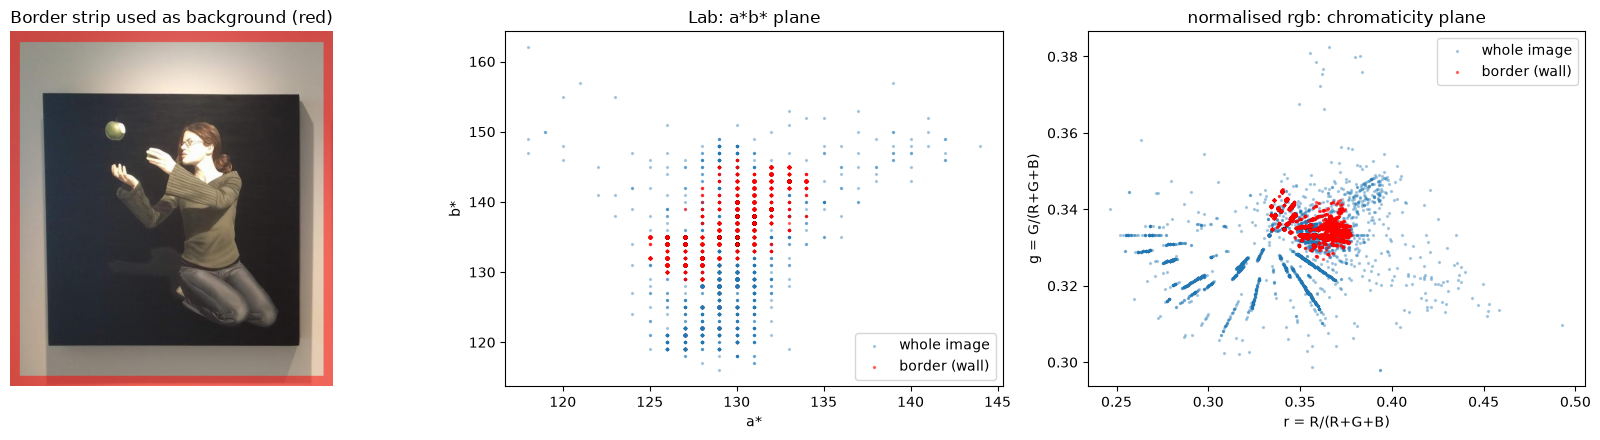

In [33]:
BORDER_RATIO = 0.03                       # outer 3% of each side is assumed to be wall
COLOR_MODELS = ["lab", "rgb"]             # "rgb" = normalised rgb (chromaticity)
SIGMA_FLOOR_VAR = {"lab": 1 / 12,         # quantisation error of 8-bit integer a*, b*
                   "rgb": 1e-8}           # chromaticity is computed in float: only avoids sigma = 0

def border_region(shape, border_ratio=BORDER_RATIO):
    #boolean map of the outer strip: border_ratio of the height (top/bottom) and of the width (left/right)
    h, w = shape[:2]
    bh, bw = max(1, round(border_ratio * h)), max(1, round(border_ratio * w))
    region = np.zeros((h, w), dtype=bool)
    region[:bh, :] = True
    region[-bh:, :] = True
    region[:, :bw] = True
    region[:, -bw:] = True
    return region   #boolean map -> corner pixels are only counted once

def color_features(image, space):
    #chroma: colour without light, (H, W, C)  /  luma: amount of light, (H, W)
    if space == "lab":
        lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB).astype(np.float32)
        return lab[..., 1:], lab[..., 0]                               # (a*, b*), L*
    if space == "rgb":
        bgr = image.astype(np.float32) + 1.0                           # +1 avoids 0/0 on black pixels
        chroma = bgr / bgr.sum(axis=-1, keepdims=True)                 # (b, g, r) / (b + g + r)
        luma = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(np.float32)
        return chroma, luma
    raise ValueError(f"Unknown colour space: {space}")

def background_model(image, space, border_ratio=BORDER_RATIO):
    #wall model learned from the border strip
    chroma, luma = color_features(image, space)
    border = border_region(luma.shape, border_ratio)
    bg_chroma = chroma[border]                                          # (N, C)
    return {"space": space, "chroma": chroma, "luma": luma,
            "mu": np.median(bg_chroma, axis=0),                         # wall colour
            "sigma": np.sqrt(bg_chroma.var(axis=0) + SIGMA_FLOOR_VAR[space]),
            "luma_wall": np.median(luma[border]) + 1e-6}                # wall lightness

#---------------------------------------------------------------------------------- 
#example: border strip + wall vs whole image in both chroma planes
ex = qsd2_imgs[1]
ex_rgb = cv2.cvtColor(ex, cv2.COLOR_BGR2RGB)
strip = border_region(ex.shape)
shown = ex_rgb.copy()
shown[strip] = (0.5 * shown[strip] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)

model_lab_ex, model_rgb_ex = background_model(ex, "lab"), background_model(ex, "rgb")
print(f"{qsd2_files[1]}")
print(f"  Lab: wall (a*, b*) = {np.round(model_lab_ex['mu'], 2)}   L*_wall = {model_lab_ex['luma_wall']:.1f}")
print(f"  rgb: wall (b, g, r) = {np.round(model_rgb_ex['mu'], 4)}   grey_wall = {model_rgb_ex['luma_wall']:.1f}")

sub = np.random.default_rng(0).choice(strip.size, size=min(5000, strip.size), replace=False)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].imshow(shown); axes[0].set_title("Border strip used as background (red)"); axes[0].axis("off")

ab_all, ab_wall = model_lab_ex["chroma"].reshape(-1, 2)[sub], model_lab_ex["chroma"][strip][::10]
axes[1].scatter(ab_all[:, 0], ab_all[:, 1], s=2, alpha=0.3, label="whole image")
axes[1].scatter(ab_wall[:, 0], ab_wall[:, 1], s=2, alpha=0.5, c="red", label="border (wall)")
axes[1].set_xlabel("a*"); axes[1].set_ylabel("b*"); axes[1].set_title("Lab: a*b* plane"); axes[1].legend()

ch_all, ch_wall = model_rgb_ex["chroma"].reshape(-1, 3)[sub], model_rgb_ex["chroma"][strip][::10]
axes[2].scatter(ch_all[:, 2], ch_all[:, 1], s=2, alpha=0.3, label="whole image")       #BGR order: 2 = r, 1 = g
axes[2].scatter(ch_wall[:, 2], ch_wall[:, 1], s=2, alpha=0.5, c="red", label="border (wall)")
axes[2].set_xlabel("r = R/(R+G+B)"); axes[2].set_ylabel("g = G/(R+G+B)")
axes[2].set_title("normalised rgb: chromaticity plane"); axes[2].legend()
plt.tight_layout(); plt.show()

### 3.2 Method A: per-channel thresholds

In [34]:
def method_a_mask(model, k=2.5):
    #wall if every chroma channel is inside [mu - k*sigma, mu + k*sigma]
    low  = model["mu"] - k * model["sigma"]
    high = model["mu"] + k * model["sigma"]
    is_wall = np.all((model["chroma"] >= low) & (model["chroma"] <= high), axis=-1)
    return ~is_wall   #True = painting

GRID_A = {"k": [1.5, 2.0, 2.5, 3.0, 4.0, 6.0]}     #same for both spaces (units of sigma)

### 3.3 Method B:  Euclidean distance

In [35]:
def chroma_distance(model):
    #Euclidean distance of every pixel to the wall colour in the chroma plane, (H, W)
    return np.sqrt(np.sum((model["chroma"] - model["mu"]) ** 2, axis=-1))

def method_b_mask(dist, tau):
    return dist > tau   #True = painting

GRID_B = {"lab": {"tau": [2, 3, 4, 6, 8, 12]},
          "rgb": {"tau": [0.01, 0.02, 0.03, 0.04, 0.06, 0.08]}}

### 3.4 Method C: Euclidean distance + dark-pixel rule

In [36]:
def luminance_ratio(model):
    #amount of light of every pixel relative to the wall, (H, W)
    return model["luma"] / model["luma_wall"]

def method_c_mask(dist, ratio, tau, tau2, rho):
    #rule 1: clearly different colour  OR  rule 2: much darker AND slightly different colour
    return (dist > tau) | ((ratio < rho) & (dist > tau2))   #True = painting

GRID_C = {"lab": {"tau": [3, 4, 6, 8, 10, 12],           "tau2": [1.0, 1.5, 2.5],        "rho": [0.6, 0.7, 0.8, 0.9]},
          "rgb": {"tau": [0.02, 0.03, 0.04, 0.06], "tau2": [0.008, 0.012, 0.02], "rho": [0.4, 0.5, 0.6, 0.7]}}

def raw_mask(model, method, params, dist=None, ratio=None):
    #common entry point for the three methods; dist / ratio can be passed precomputed (grid search)
    if method == "A":
        return method_a_mask(model, **params)
    dist = chroma_distance(model) if dist is None else dist
    if method == "B":
        return method_b_mask(dist, **params)
    ratio = luminance_ratio(model) if ratio is None else ratio
    return method_c_mask(dist, ratio, **params)

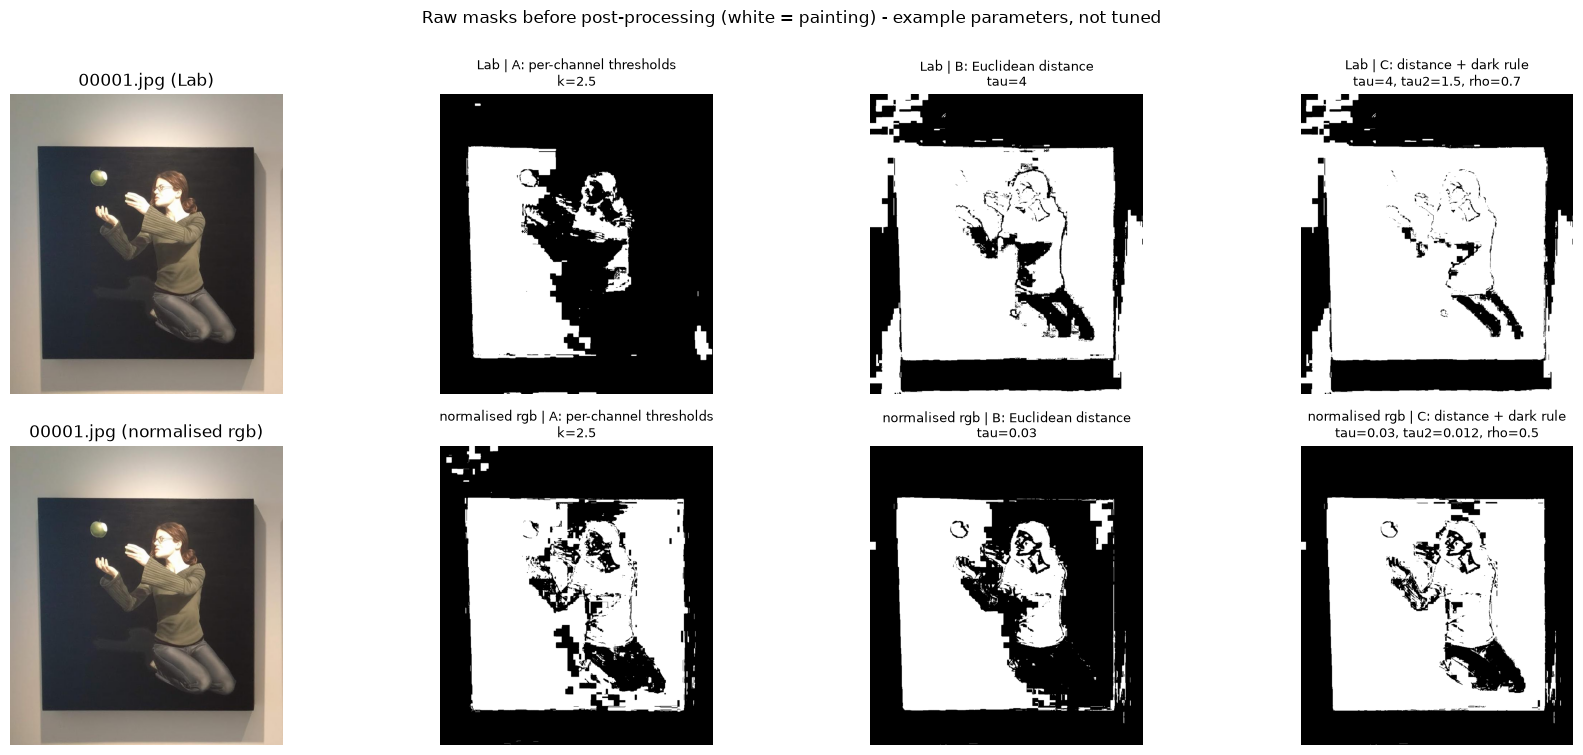

In [37]:
#example: raw masks of the 3 methods in the 2 colour spaces (example parameters, NOT tuned)
EXAMPLE_PARAMS = {
    "lab": {"A": {"k": 2.5}, "B": {"tau": 4},    "C": {"tau": 4,    "tau2": 1.5,   "rho": 0.7}},
    "rgb": {"A": {"k": 2.5}, "B": {"tau": 0.03}, "C": {"tau": 0.03, "tau2": 0.012, "rho": 0.5}},
}
METHOD_NAMES = {"A": "A: per-channel thresholds", "B": "B: Euclidean distance", "C": "C: distance + dark rule"}
SPACE_NAMES  = {"lab": "Lab", "rgb": "normalised rgb"}

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for row, (space, model) in enumerate([("lab", model_lab_ex), ("rgb", model_rgb_ex)]):
    axes[row, 0].imshow(ex_rgb); axes[row, 0].set_title(f"{qsd2_files[1]} ({SPACE_NAMES[space]})")
    for col, method in enumerate(["A", "B", "C"], start=1):
        params = EXAMPLE_PARAMS[space][method]
        axes[row, col].imshow(raw_mask(model, method, params), cmap="gray")
        axes[row, col].set_title(f"{SPACE_NAMES[space]} | {METHOD_NAMES[method]}\n"
                                 + ", ".join(f"{k}={v}" for k, v in params.items()), fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("Raw masks before post-processing (white = painting) - example parameters, not tuned", y=1.0)
plt.tight_layout(); plt.show()

### 3.4 Morphological post-processing: hole filling + largest connected component

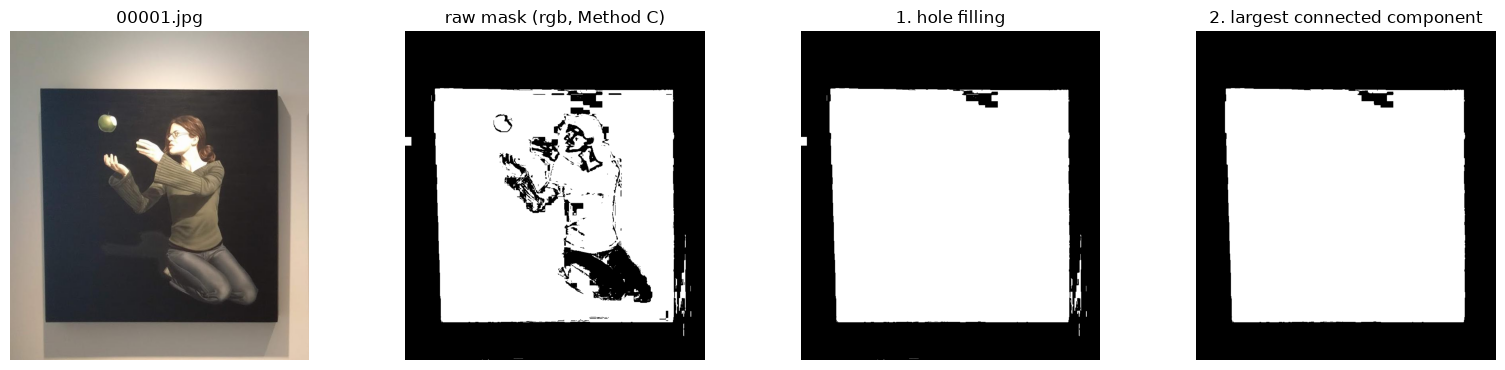

In [38]:
POST_MODES = ["none", "fill+lcc"]

def fill_holes(mask):
    #G&W 9.5.9: flood the background from the border; whatever background is not reached is a hole
    padded = np.pad(mask.astype(np.uint8), 1, constant_values=0)   #padding guarantees (0,0) is background
    ff_mask = np.zeros((padded.shape[0] + 2, padded.shape[1] + 2), np.uint8)
    cv2.floodFill(padded, ff_mask, (0, 0), 1)
    holes = padded[1:-1, 1:-1] == 0
    return mask.astype(bool) | holes

def largest_component(mask):
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    if n <= 1:                     #only background
        return mask.astype(bool)
    biggest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return labels == biggest

def postprocess_mask(mask, mode="fill+lcc"):
    if mode == "none":
        return mask.astype(bool)
    m = largest_component(fill_holes(mask))
    if not m.any():                #nothing detected: fall back to the whole image
        m = np.ones_like(m, dtype=bool)
    return m

def segment_painting(image, space="rgb", method="C", params=None, post="fill+lcc"):
    #full Task 3 pipeline for one image -> uint8 mask (0/255), same size as the image
    params = EXAMPLE_PARAMS[space][method] if params is None else params
    model = background_model(image, space)
    return postprocess_mask(raw_mask(model, method, params), post).astype(np.uint8) * 255

#---------------------------------------------------------------------------------- 
#example: effect of each step (normalised rgb, Method C, example parameters)
raw_ex = raw_mask(model_rgb_ex, "C", EXAMPLE_PARAMS["rgb"]["C"])
filled_ex = fill_holes(raw_ex)
steps = {"raw mask (rgb, Method C)": raw_ex, "1. hole filling": filled_ex,
         "2. largest connected component": largest_component(filled_ex)}

fig, axes = plt.subplots(1, len(steps) + 1, figsize=(16, 3.8))
axes[0].imshow(ex_rgb); axes[0].set_title(qsd2_files[1])
for ax, (name, m) in zip(axes[1:], steps.items()):
    ax.imshow(m, cmap="gray"); ax.set_title(name)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## Task 4: Background removal evaluation

In [39]:
EPS = 1e-10

#ground-truth masks (same name as the query, .png)
qsd2_gt_masks = []
for f in qsd2_files:
    gt_path = os.path.join(qsd2_path, os.path.splitext(f)[0] + ".png")
    gt = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
    if gt is None:
        raise IOError(f"Could not read GT mask {gt_path}")
    qsd2_gt_masks.append(gt > 0)

def mask_counts(pred, gt):
    pred, gt = pred > 0, gt > 0
    assert pred.shape == gt.shape, f"Shape mismatch {pred.shape} vs {gt.shape}"
    tp = np.count_nonzero(pred & gt)
    fp = np.count_nonzero(pred & ~gt)
    fn = np.count_nonzero(~pred & gt)
    return tp, fp, fn

def prf(tp, fp, fn):
    p = tp / (tp + fp + EPS)
    r = tp / (tp + fn + EPS)
    return p, r, 2 * p * r / (p + r + EPS)

def summarize_counts(counts):
    #counts: list of (TP, FP, FN), one per image
    counts = np.asarray(counts, dtype=np.float64)
    per_image = np.array([prf(*c) for c in counts])                       #(N, 3)
    mean_p, mean_r, mean_f1 = per_image.mean(axis=0)
    glob_p, glob_r, glob_f1 = prf(*counts.sum(axis=0))
    summary = {"Precision": mean_p, "Recall": mean_r, "F1": mean_f1,
               "Global P": glob_p, "Global R": glob_r, "Global F1": glob_f1}
    return summary, per_image

def evaluate_masks(pred_masks, gt_masks):
    return summarize_counts([mask_counts(p, g) for p, g in zip(pred_masks, gt_masks)])

### 4.1 Grid search and comparison of methods

In [40]:
def params_label(params):
    return ", ".join(f"{k}={v}" for k, v in params)

# configurations without post-processing: (space, method, params)   params = tuple of (name, value)
base_configs = []
for space in COLOR_MODELS:
    base_configs += [(space, "A", (("k", k),)) for k in GRID_A["k"]]
    base_configs += [(space, "B", (("tau", t),)) for t in GRID_B[space]["tau"]]
    grid_c = GRID_C[space]
    base_configs += [(space, "C", (("tau", t), ("tau2", t2), ("rho", r)))
                     for t in grid_c["tau"] for t2 in grid_c["tau2"] if t2 < t for r in grid_c["rho"]]
configs = [(space, method, params, post) for space, method, params in base_configs for post in POST_MODES]
print(f"{len(base_configs)} colour configurations x {len(POST_MODES)} post-processing modes = {len(configs)}")

# loop over images: the wall model and the maps are computed once per image and colour space
# every raw mask is computed once and post-processed in every mode; only (TP, FP, FN) are kept
counts = {cfg: [] for cfg in configs}
for img, gt in tqdm(zip(qsd2_imgs, qsd2_gt_masks), total=len(qsd2_imgs), desc="Grid search"):
    cache = {}
    for space in COLOR_MODELS:
        model = background_model(img, space)
        cache[space] = (model, chroma_distance(model), luminance_ratio(model))
    for space, method, params in base_configs:
        model, dist, ratio = cache[space]
        raw = raw_mask(model, method, dict(params), dist, ratio)
        for post in POST_MODES:
            counts[(space, method, params, post)].append(mask_counts(postprocess_mask(raw, post), gt))
    del cache

# results table
rows = []
for cfg_id, ((space, method, params, post), cfg_counts) in enumerate(counts.items()):
    summary, _ = summarize_counts(cfg_counts)
    rows.append({"cfg_id": cfg_id, "Space": SPACE_NAMES[space], "Method": method,
                 "Params": params_label(params), "Post": post, **summary, **dict(params)})

num_cols = ["Precision", "Recall", "F1", "Global P", "Global R", "Global F1"]
df_grid_order = pd.DataFrame(rows)                    #keeps the grid order
df_grid_order[num_cols] = df_grid_order[num_cols].round(4)
df_bg = df_grid_order.sort_values("F1", ascending=False).reset_index(drop=True)
show_cols = ["Space", "Method", "Params", "Post"] + num_cols

# tables for the slides
print("Methods:", " | ".join(METHOD_NAMES.values()))
print("\n=== TOP 10 CONFIGURATIONS (QSD2-W2, ranked by mean F1) ===")
display(df_bg[show_cols].head(10))

best_per_group = (df_bg.loc[df_bg.groupby(["Space", "Method", "Post"])["F1"].idxmax()]
                  .sort_values(["Post", "F1"], ascending=[True, False]).reset_index(drop=True))
print("\n=== BEST CONFIGURATION PER COLOUR SPACE / METHOD / POST-PROCESSING ===")
display(best_per_group[show_cols])

print("\n=== MAIN COMPARISON: best mean F1 per method and colour space (post = fill+lcc) ===")
display(df_bg[df_bg.Post == "fill+lcc"].pivot_table(index="Method", columns="Space", values="F1", aggfunc="max"))

print("\n=== EFFECT OF THE POST-PROCESSING: best mean F1 ===")
display(df_bg.pivot_table(index=["Space", "Method"], columns="Post", values="F1", aggfunc="max")[POST_MODES])

for space in COLOR_MODELS:
    df_c = df_bg[(df_bg.Method == "C") & (df_bg.Space == SPACE_NAMES[space]) & (df_bg.Post == "fill+lcc")]
    print(f"\n=== METHOD C ({SPACE_NAMES[space]}): best mean F1 (over tau2) for each tau / rho ===")
    display(df_c.pivot_table(index="tau", columns="rho", values="F1", aggfunc="max"))

# save
output_dir = "results"
os.makedirs(output_dir, exist_ok=True)
df_bg.to_csv(os.path.join(output_dir, "bg_removal_grid_search.csv"), index=False)
best_per_group.to_csv(os.path.join(output_dir, "bg_removal_best_per_method.csv"), index=False)

best_cfg = df_bg.iloc[0]
best_cfg_tuple = configs[int(best_cfg.cfg_id)]
print(f"\nBest: {best_cfg.Space} | Method {best_cfg.Method} | {best_cfg.Params} | post={best_cfg.Post} "
      f"-> P={best_cfg.Precision:.4f}  R={best_cfg.Recall:.4f}  F1={best_cfg.F1:.4f}")

140 colour configurations x 2 post-processing modes = 280


Grid search: 100%|██████████| 30/30 [00:20<00:00,  1.47it/s]

Methods: A: per-channel thresholds | B: Euclidean distance | C: distance + dark rule

=== TOP 10 CONFIGURATIONS (QSD2-W2, ranked by mean F1) ===


,Space,Method,Params,Post,Precision,Recall,F1,Global P,Global R,Global F1
0,Lab,C,"tau=10, tau2=1.5, rho=0.6",fill+lcc,0.9655,0.9838,0.9740,0.9829,0.9888,0.9859
1,Lab,C,"tau=10, tau2=1.0, rho=0.6",fill+lcc,0.9641,0.9843,0.9734,0.9825,0.9890,0.9858
2,Lab,C,"tau=8, tau2=1.5, rho=0.6",fill+lcc,0.9562,0.9888,0.9715,0.9700,0.9920,0.9809
3,Lab,C,"tau=8, tau2=1.0, rho=0.6",fill+lcc,0.9548,0.9893,0.9710,0.9696,0.9922,0.9808
4,Lab,C,"tau=10, tau2=1.5, rho=0.7",fill+lcc,0.9548,0.9889,0.9710,0.9776,0.9903,0.9839
5,Lab,C,"tau=10, tau2=1.0, rho=0.7",fill+lcc,0.9528,0.9894,0.9701,0.9770,0.9905,0.9837
6,Lab,C,"tau=8, tau2=1.5, rho=0.7",fill+lcc,0.9476,0.9928,0.9690,0.9656,0.9931,0.9792
7,normalised rgb,C,"tau=0.03, tau2=0.012, rho=0.4",fill+lcc,0.9506,0.9882,0.9683,0.9700,0.9920,0.9808
8,Lab,C,"tau=8, tau2=1.0, rho=0.7",fill+lcc,0.9456,0.9933,0.9682,0.9650,0.9933,0.9790
9,normalised rgb,C,"tau=0.03, tau2=0.008, rho=0.4",fill+lcc,0.9476,0.9883,0.9669,0.9694,0.9920,0.9806



=== BEST CONFIGURATION PER COLOUR SPACE / METHOD / POST-PROCESSING ===


...


=== METHOD C (Lab): best mean F1 (over tau2) for each tau / rho ===


rho,0.6,0.7,0.8,0.9
tau,,,,
3.0,0.9084,0.9080,0.9056,0.9026
4.0,0.9430,0.9384,0.9280,0.9317
6.0,0.9642,0.9611,0.9486,0.9330
8.0,0.9715,0.9690,0.9570,0.9387
10.0,0.9740,0.9710,0.9591,0.9416
12.0,0.9458,0.9415,0.9480,0.9313



=== METHOD C (normalised rgb): best mean F1 (over tau2) for each tau / rho ===


rho,0.4,0.5,0.6,0.7
tau,,,,
0.02,0.9448,0.9435,0.9434,0.9407
0.03,0.9683,0.9660,0.9655,0.9622
0.04,0.9658,0.9635,0.9662,0.9618
0.06,0.9214,0.9204,0.9290,0.9240



Best: Lab | Method C | tau=10, tau2=1.5, rho=0.6 | post=fill+lcc -> P=0.9655  R=0.9838  F1=0.9740


### 4.2 Qualitative results: worst and best cases

=== PER-IMAGE RESULTS OF THE BEST CONFIGURATION (worst first) ===


,Query,Precision,Recall,F1
0,00013.jpg,0.8132,0.9331,0.8691
1,00014.jpg,0.8285,0.9622,0.8904
2,00000.jpg,0.8623,0.9995,0.9259
3,00004.jpg,0.8929,0.9858,0.9371
4,00015.jpg,0.9122,0.9873,0.9482
5,00029.jpg,0.9292,1.0000,0.9633
6,00028.jpg,0.9914,0.9385,0.9642
7,00002.jpg,0.9844,0.9498,0.9668
8,00018.jpg,0.9885,0.9539,0.9709
9,00007.jpg,0.9596,0.9905,0.9748


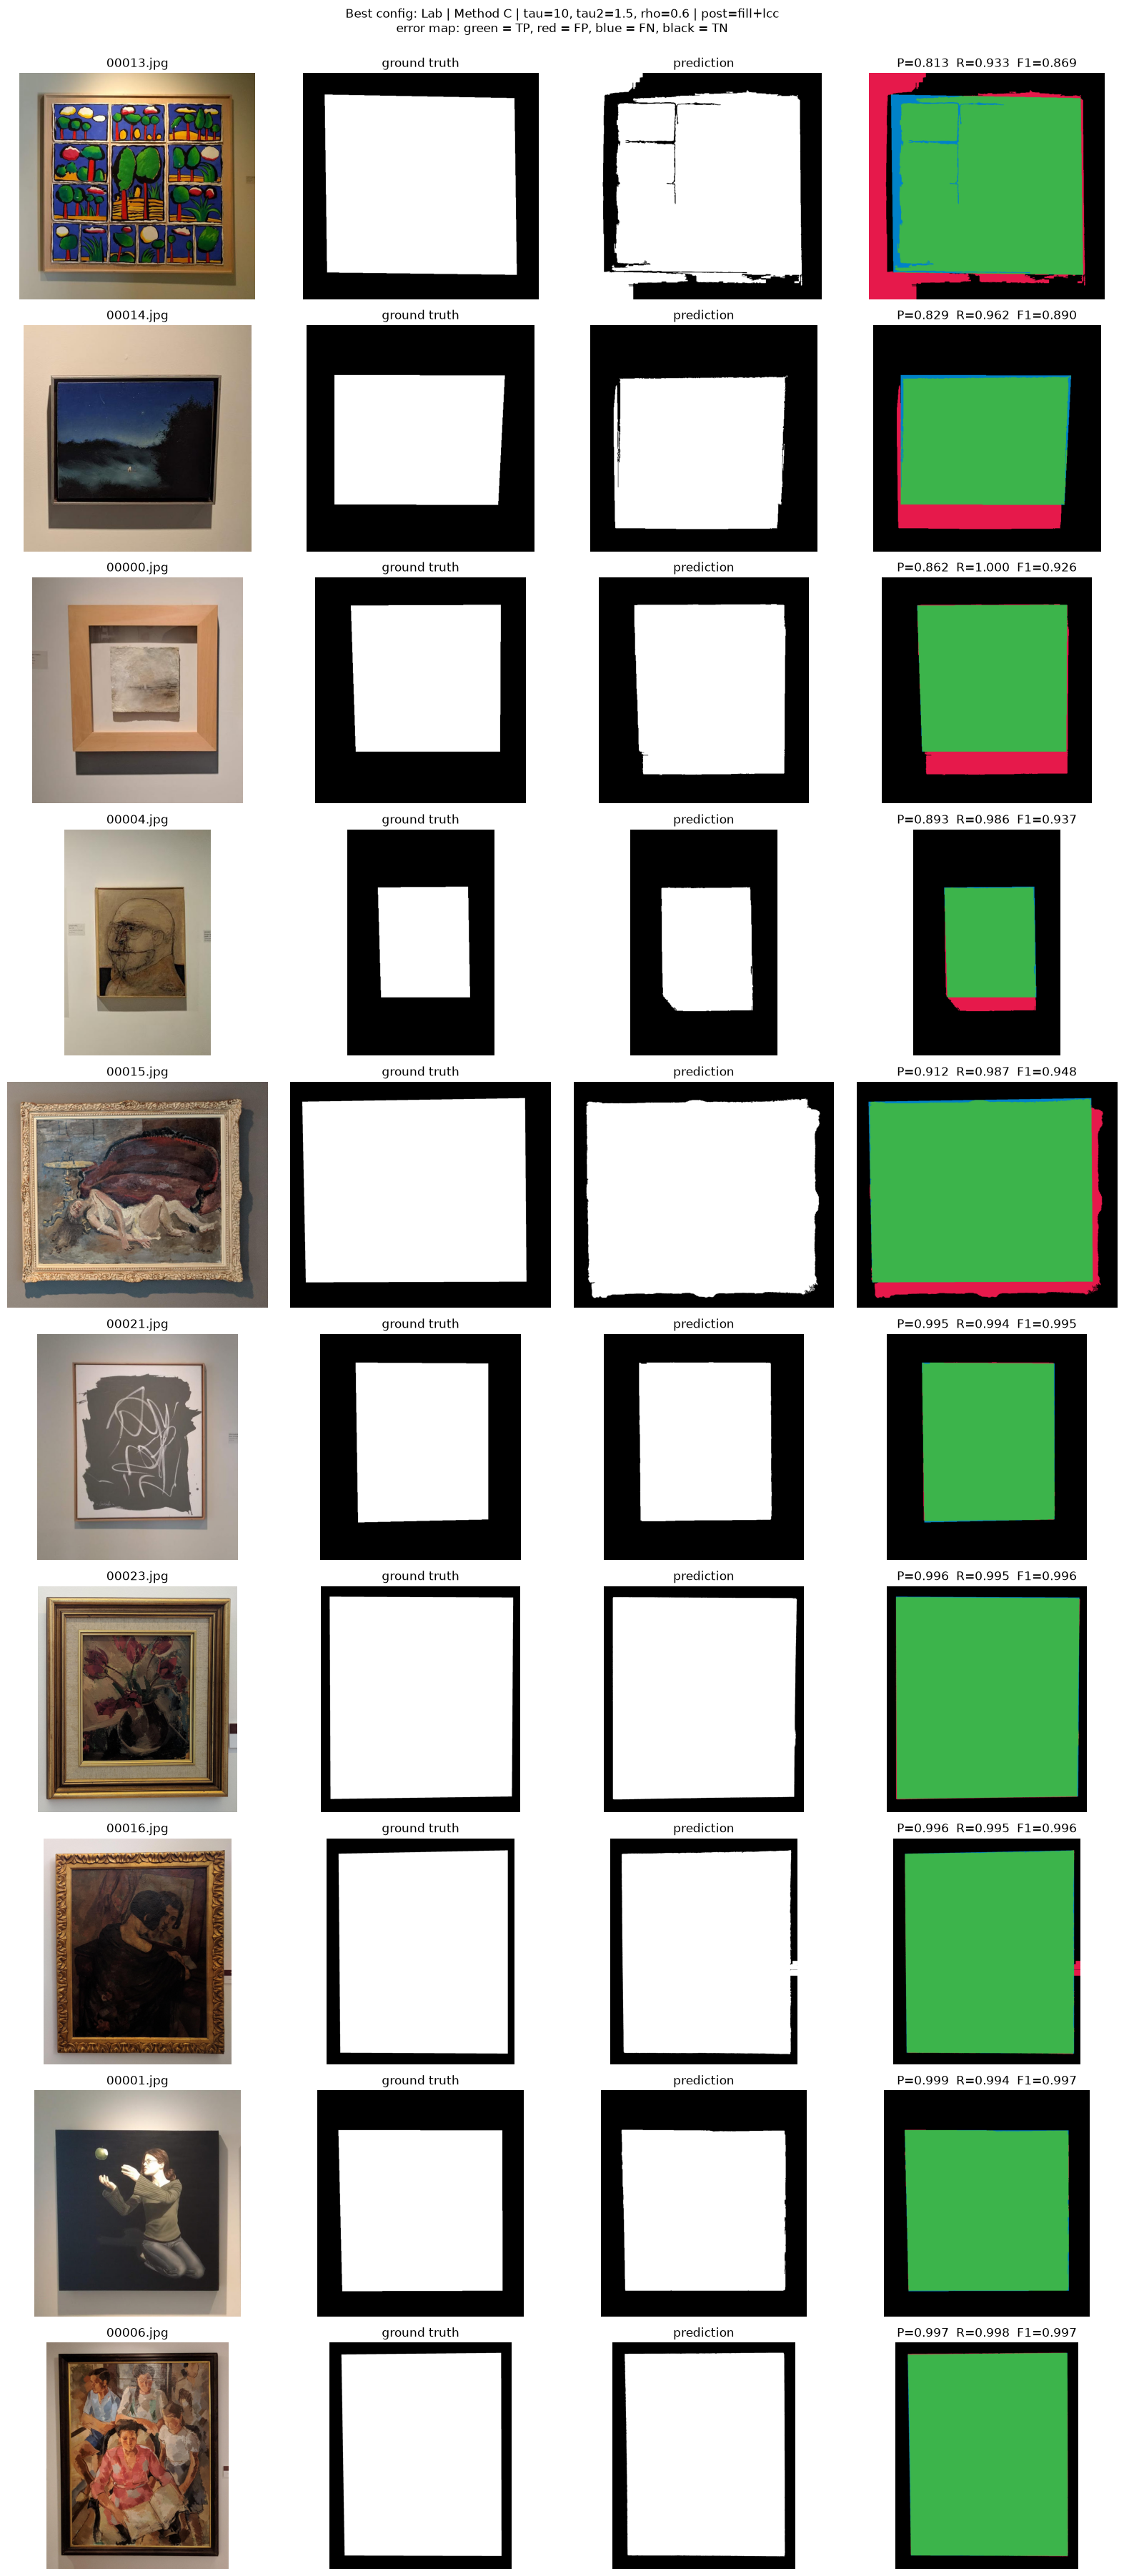

In [41]:
def predict_config(space, method, params, post):
    #masks of every query for one configuration
    return [segment_painting(img, space, method, dict(params), post) for img in qsd2_imgs]

def error_map(pred, gt):
    pred, gt = pred > 0, gt > 0
    out = np.zeros(pred.shape + (3,), np.uint8)          #TN: black
    out[pred & gt]  = (60, 180, 75)                      #TP: green
    out[pred & ~gt] = (230, 25, 75)                      #FP: red
    out[~pred & gt] = (0, 130, 200)                      #FN: blue
    return out

best_preds = predict_config(*best_cfg_tuple)
_, per_image = evaluate_masks(best_preds, qsd2_gt_masks)

df_per_image = pd.DataFrame(per_image, columns=["Precision", "Recall", "F1"]).round(4)
df_per_image.insert(0, "Query", qsd2_files)
df_per_image = df_per_image.sort_values("F1").reset_index(drop=True)
print("=== PER-IMAGE RESULTS OF THE BEST CONFIGURATION (worst first) ===")
display(df_per_image)

shown_idx = list(df_per_image.index[:5]) + list(df_per_image.index[-5:])   #5 worst + 5 best
fig, axes = plt.subplots(len(shown_idx), 4, figsize=(16, 3.6 * len(shown_idx)))
for row, idx in zip(axes, shown_idx):
    q = qsd2_files.index(df_per_image.loc[idx, "Query"])
    img, pred, gt = qsd2_imgs[q], best_preds[q], qsd2_gt_masks[q]
    r = df_per_image.loc[idx]
    row[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); row[0].set_title(qsd2_files[q])
    row[1].imshow(gt, cmap="gray");   row[1].set_title("ground truth")
    row[2].imshow(pred, cmap="gray"); row[2].set_title("prediction")
    row[3].imshow(error_map(pred, gt))
    row[3].set_title(f"P={r.Precision:.3f}  R={r.Recall:.3f}  F1={r.F1:.3f}")
    for ax in row: ax.axis("off")
plt.suptitle(f"Best config: {best_cfg.Space} | Method {best_cfg.Method} | {best_cfg.Params} | post={best_cfg.Post}\n"
             "error map: green = TP, red = FP, blue = FN, black = TN", y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "bg_removal_worst_best.png"), dpi=120, bbox_inches="tight")
plt.show()

## Task 5: Retrieval on QSD2-W2 (background removed)

Each QSD2 photo is segmented with the best Task 3/4 configuration, the descriptor is computed **on the painting only** (Task 3, last bullet) and the BBDD is ranked with the best W2 descriptor / distance from Task 2 (Block 8x8 | YCrCb 2D | 16 bins, chi2). Nothing is re-tuned on QSD2.

Ways of describing the query (BBDD images are already cropped paintings, so they are described as in Task 2):
- **full**: whole photo, no background removal (baseline)
- **masked**: histogram of the painting pixels only (mask passed to `calcHist`); the grid still covers the whole photo
- **crop**: crop to the bounding box of the mask, so the painting fills the 8x8 grid like a BBDD image
- **crop+mask**: crop, and also ignore the wall pixels left inside the box

The same is done with the GT masks, which gives the best result this descriptor could reach with perfect background removal.

In [42]:
#needs: qsd2_imgs, qsd2_files, qsd2_gt_masks, best_preds (masks of the best Task 4 config), best_w2_descriptor, MEASURES, kdd_mapk
BEST_DISTANCE = "chi2"
FG_MODES = ["full", "masked", "crop", "crop+mask"]

with open(os.path.join(qsd2_path, "gt_corresps.pkl"), "rb") as f:
    qsd2_actual = [[int(i) for i in query_gt] for query_gt in pickle.load(f)]
assert len(qsd2_actual) == len(qsd2_files), "QSD2 GT does not match the number of queries"

def mask_bbox(mask):
    #bounding box (y0, y1, x0, x1) of the foreground; whole image if the mask is empty
    ys, xs = np.nonzero(mask)
    if ys.size == 0:
        return 0, mask.shape[0], 0, mask.shape[1]
    return ys.min(), ys.max() + 1, xs.min(), xs.max() + 1

def foreground_descriptor(image, mask, descriptor_fn, mode="crop"):
    #descriptor of the painting only
    if mode == "full":
        return descriptor_fn(image)
    if mode == "masked":
        return descriptor_fn(image, mask=mask)
    y0, y1, x0, x1 = mask_bbox(mask)
    if mode == "crop":
        return descriptor_fn(image[y0:y1, x0:x1])
    if mode == "crop+mask":
        return descriptor_fn(image[y0:y1, x0:x1], mask=mask[y0:y1, x0:x1])
    raise ValueError(f"Unknown mode: {mode}")

bbdd_desc_w2 = compute_descriptors(bbdd_imgs, best_w2_descriptor)   #BBDD described as in Task 2

def retrieve_paintings(images, masks, mode="crop", descriptor_fn=best_w2_descriptor,
                       measure=MEASURES[BEST_DISTANCE], k=10):
    #masks: one mask per image (0/255 or bool), from segment_painting or the GT
    q_desc = np.stack([foreground_descriptor(im, m, descriptor_fn, mode) for im, m in zip(images, masks)])
    return retrieve_topk(q_desc.astype(np.float32), bbdd_desc_w2, bbdd_ids, measure, k=k)

#our masks (best Task 4 config) and GT masks
mask_sets = {"ours": best_preds, "GT": [m.astype(np.uint8) * 255 for m in qsd2_gt_masks]}

rows, qsd2_predictions = [], {}
for mask_name, masks in mask_sets.items():
    for mode in FG_MODES:
        if mode == "full" and mask_name != "ours":
            continue                                     #"full" does not use the mask
        preds = retrieve_paintings(qsd2_imgs, masks, mode)
        qsd2_predictions[(mask_name, mode)] = preds
        rows.append({"Masks": "none" if mode == "full" else mask_name, "Query descriptor": mode,
                     "MAP@1": kdd_mapk(qsd2_actual, preds, k=1), "MAP@5": kdd_mapk(qsd2_actual, preds, k=5),
                     "MAP@10": kdd_mapk(qsd2_actual, preds, k=10)})

df_task5 = pd.DataFrame(rows).round(4)
print(f"=== TASK 5: QSD2-W2 retrieval (Block 8x8 | YCrCb 2D | 16 bins, {BEST_DISTANCE}) ===")
display(df_task5)

#method used for QSD2 (and later QST2): best mode with OUR masks
best_t5 = df_task5[df_task5.Masks == "ours"].sort_values(["MAP@1", "MAP@5"], ascending=False).iloc[0]
QS2_MODE = best_t5["Query descriptor"]
print(f"\nSelected: our masks + '{QS2_MODE}' -> MAP@1 = {best_t5['MAP@1']:.4f}, MAP@5 = {best_t5['MAP@5']:.4f}")

=== TASK 5: QSD2-W2 retrieval (Block 8x8 | YCrCb 2D | 16 bins, chi2) ===


,Masks,Query descriptor,MAP@1,MAP@5,MAP@10
0,none,full,0.2333,0.2483,0.2539
1,ours,masked,0.4333,0.4733,0.4800
2,ours,crop,0.7000,0.7333,0.7381
3,ours,crop+mask,0.7000,0.7333,0.7381
4,GT,masked,0.4333,0.4667,0.4825
5,GT,crop,0.7000,0.7333,0.7423
6,GT,crop+mask,0.7000,0.7333,0.7437



Selected: our masks + 'crop' -> MAP@1 = 0.7000, MAP@5 = 0.7333


In [43]:
#correspondences for each painting (top-10 BBDD ids per query) with the selected method
from utils.extra_descriptors import save_results

qsd2_result = qsd2_predictions[("ours", QS2_MODE)]

def gt_rank(actual, predicted):
    #1-based position of the first correct id, None if it is not in the list
    return next((i + 1 for i, p in enumerate(predicted) if p in actual), None)

df_qsd2 = pd.DataFrame({
    "Query": qsd2_files,
    "GT": [a[0] if len(a) == 1 else a for a in qsd2_actual],
    "Top-5": [p[:5] for p in qsd2_result],
    "GT rank (top-10)": pd.array([gt_rank(a, p) for a, p in zip(qsd2_actual, qsd2_result)], dtype="Int64"),
})
print(f"=== QSD2-W2 correspondences (our masks + {QS2_MODE}) ===")
display(df_qsd2)

save_results(qsd2_result, os.path.join("results", "QSD2", "result.pkl"))   #same format as the QST submission
print("Saved results/QSD2/result.pkl:", len(qsd2_result), "queries x", len(qsd2_result[0]), "BBDD ids")

=== QSD2-W2 correspondences (our masks + crop) ===


,Query,GT,Top-5,GT rank (top-10)
0,00000.jpg,100,"[13, 127, 110, 184, 90]",<NA>
1,00001.jpg,219,"[10, 286, 80, 126, 279]",<NA>
2,00002.jpg,250,"[250, 31, 114, 109, 276]",1
3,00003.jpg,25,"[25, 158, 200, 16, 143]",1
4,00004.jpg,22,"[22, 205, 16, 13, 31]",1
5,00005.jpg,215,"[215, 88, 147, 163, 225]",1
6,00006.jpg,81,"[81, 42, 82, 95, 154]",1
7,00007.jpg,184,"[184, 258, 106, 35, 5]",1
8,00008.jpg,177,"[177, 139, 138, 174, 71]",1
9,00009.jpg,203,"[203, 194, 205, 150, 191]",1


Saved results/QSD2/result.pkl: 30 queries x 10 BBDD ids


9 / 30 queries with a wrong top-1: 00000.jpg, 00001.jpg, 00010.jpg, 00012.jpg, 00014.jpg, 00018.jpg, 00020.jpg, 00021.jpg, 00025.jpg


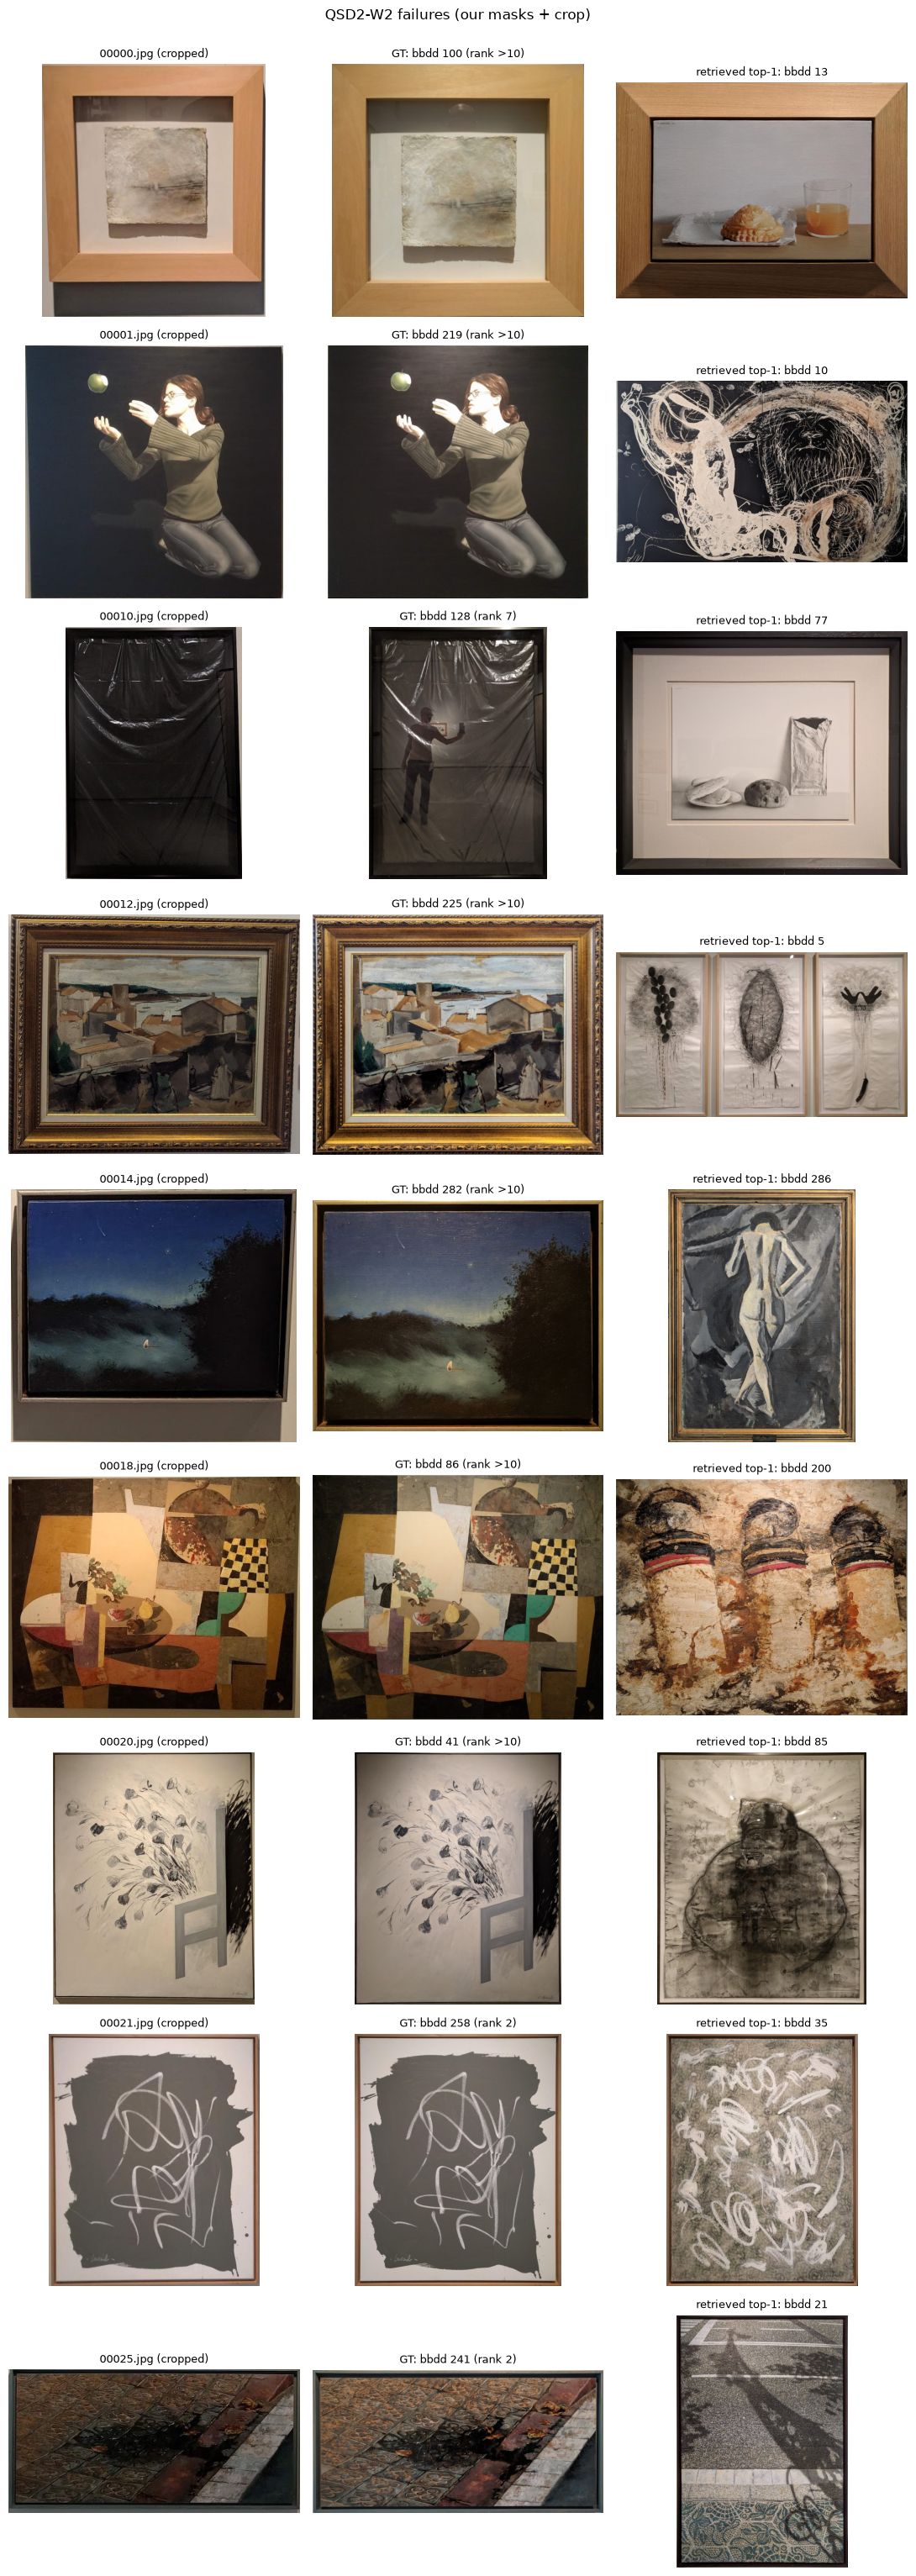

In [44]:
#queries whose top-1 is wrong: query painting (cropped with our mask), correct BBDD image, retrieved top-1
misses = [q for q, p in enumerate(qsd2_result) if p[0] not in qsd2_actual[q]]
print(f"{len(misses)} / {len(qsd2_result)} queries with a wrong top-1:", ", ".join(qsd2_files[q] for q in misses))

if misses:
    bbdd_by_id = dict(zip(bbdd_ids.tolist(), bbdd_imgs))
    fig, axes = plt.subplots(len(misses), 3, figsize=(11, 3.4 * len(misses)), squeeze=False)
    for row, q in zip(axes, misses):
        y0, y1, x0, x1 = mask_bbox(best_preds[q])
        gt_id, top1 = qsd2_actual[q][0], qsd2_result[q][0]
        rank = gt_rank(qsd2_actual[q], qsd2_result[q])
        shown = [(f"{qsd2_files[q]} (cropped)", qsd2_imgs[q][y0:y1, x0:x1]),
                 (f"GT: bbdd {gt_id} (rank {rank if rank else '>10'})", bbdd_by_id[gt_id]),
                 (f"retrieved top-1: bbdd {top1}", bbdd_by_id[top1])]
        for ax, (title, im) in zip(row, shown):
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(title, fontsize=9); ax.axis("off")
    plt.suptitle(f"QSD2-W2 failures (our masks + {QS2_MODE})", y=1.0)
    plt.tight_layout()
    plt.savefig(os.path.join("results", "qsd2_retrieval_failures.png"), dpi=110, bbox_inches="tight")
    plt.show()

## Task 6: Blind submission for QST1-W2 and QST2-W2

Nothing is tuned on the test sets: every choice comes from the development sets.
- **QST1-W2** (cropped paintings): best W2 descriptor and distance from Task 2 (Block 8x8 | YCrCb 2D | 16 bins), computed on the whole image.
- **QST2-W2** (paintings on a wall): best background-removal configuration from Task 4, then the descriptor on the painting only with the mode selected in Task 5 (`QS2_MODE`), same distance as Task 5.

Output: for each query, a list of the K=10 best BBDD ids (python list of lists of `int`), and for QST2 the binary masks with the same name as the query and `.png` extension

In [45]:
#needs: bbdd_ids, db_desc (BBDD, Task 2), best_w2_descriptor, best_w2_row, MEASURES, read_image, return_number
K_SUBMIT = 10
qst1_path = "./data/qst_w2/qst1_w2"
qst2_path = "./data/qst_w2/qst2_w2"
qst1_out = os.path.join("results", "QST1", "method1")
qst2_out = os.path.join("results", "QST2", "method1")

def load_query_set(folder):
    #queries in natural order (00000.jpg, 00001.jpg, ...): the i-th list of the .pkl must be the i-th query
    files = sorted([f for f in os.listdir(folder) if f.lower().endswith(".jpg")], key=return_number)
    return files, [read_image(os.path.join(folder, f)) for f in files]

def check_submission(preds, n_queries, k=K_SUBMIT):
    #list of lists of python ints, one list of k distinct ids per query, all ids in the BBDD
    assert isinstance(preds, list) and len(preds) == n_queries, f"{len(preds)} lists for {n_queries} queries"
    valid = set(bbdd_ids.tolist())
    for p in preds:
        assert isinstance(p, list) and len(p) == k and len(set(p)) == k, p
        assert all(type(i) is int and i in valid for i in p), p

#QST1: same descriptor and distance as the best Task 2 result on QSD1
qst1_files, qst1_imgs = load_query_set(qst1_path)
QST1_DISTANCE = best_w2_row["Distance"]
qst1_desc = compute_descriptors(qst1_imgs, best_w2_descriptor)
qst1_result = retrieve_topk(qst1_desc, db_desc, bbdd_ids, MEASURES[QST1_DISTANCE], k=K_SUBMIT)

check_submission(qst1_result, len(qst1_files))
save_results(qst1_result, os.path.join(qst1_out, "result.pkl"))
print(f"QST1: {len(qst1_files)} queries, Block 8x8 | YCrCb 2D | 16 bins, {QST1_DISTANCE}")
print(f"Saved {qst1_out}/result.pkl: {len(qst1_result)} lists x {K_SUBMIT} BBDD ids, e.g. {qst1_files[0]} -> {qst1_result[0]}")

QST1: 30 queries, Block 8x8 | YCrCb 2D | 16 bins, chi2
Saved results/QST1/method1/result.pkl: 30 lists x 10 BBDD ids, e.g. 00000.jpg -> [194, 246, 258, 184, 35, 106, 226, 40, 5, 187]


In [46]:
#needs: best_cfg, best_cfg_tuple (Task 4), segment_painting, retrieve_paintings, QS2_MODE, BEST_DISTANCE (Task 5)
qst2_files, qst2_imgs = load_query_set(qst2_path)

#1. background removal with our best Task 4 configuration (colour only, no GT)
space, method, params, post = best_cfg_tuple
qst2_masks = [segment_painting(img, space, method, dict(params), post) for img in qst2_imgs]

#2. masks: same name as the query, .png, binary 0/255, same size as the image
os.makedirs(qst2_out, exist_ok=True)
for f, img, m in zip(qst2_files, qst2_imgs, qst2_masks):
    assert m.shape == img.shape[:2] and m.dtype == np.uint8 and set(np.unique(m)) <= {0, 255}
    cv2.imwrite(os.path.join(qst2_out, os.path.splitext(f)[0] + ".png"), m)

#3. retrieval on the painting only, with the mode and distance selected on QSD2 (Task 5)
qst2_result = retrieve_paintings(qst2_imgs, qst2_masks, QS2_MODE, measure=MEASURES[BEST_DISTANCE], k=K_SUBMIT)

check_submission(qst2_result, len(qst2_files))
save_results(qst2_result, os.path.join(qst2_out, "result.pkl"))
fg = np.array([(m > 0).mean() for m in qst2_masks])
print(f"QST2: {len(qst2_files)} queries | masks: {best_cfg.Space} | Method {best_cfg.Method} | {best_cfg.Params} | post={best_cfg.Post}"
      f" | descriptor mode '{QS2_MODE}', {BEST_DISTANCE}")
print(f"Foreground fraction of the masks: min {fg.min():.2f}, median {np.median(fg):.2f}, max {fg.max():.2f}")
print(f"Saved {qst2_out}/result.pkl ({len(qst2_result)} lists x {K_SUBMIT} ids) and {len(qst2_masks)} masks (.png)")

QST2: 30 queries | masks: Lab | Method C | tau=10, tau2=1.5, rho=0.6 | post=fill+lcc | descriptor mode 'crop', chi2
Foreground fraction of the masks: min 0.05, median 0.53, max 0.84
Saved results/QST2/method1/result.pkl (30 lists x 10 ids) and 30 masks (.png)


In [47]:
#visual check (no GT on the test sets): QST2 query, our mask, the crop used for the descriptor and the top-1 BBDD image
bbdd_by_id = dict(zip(bbdd_ids.tolist(), bbdd_imgs))
fig, axes = plt.subplots(len(qst2_files), 4, figsize=(14, 3.0 * len(qst2_files)), squeeze=False)
for row, f, img, m, p in zip(axes, qst2_files, qst2_imgs, qst2_masks, qst2_result):
    y0, y1, x0, x1 = mask_bbox(m)
    shown = [(f, img), (f"mask ({(m > 0).mean():.0%} painting)", m),
             ("crop used for the descriptor", img[y0:y1, x0:x1]), (f"top-1: bbdd {p[0]}", bbdd_by_id[p[0]])]
    for ax, (title, im) in zip(row, shown):
        ax.imshow(im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2RGB), cmap="gray")
        ax.set_title(title, fontsize=9); ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join("results", "qst2_masks_top1.png"), dpi=80, bbox_inches="tight")
plt.close(fig)   #30 rows: saved to file instead of embedded, to keep the notebook small

#QST1: query and top-1 BBDD image
fig, axes = plt.subplots(5, 12, figsize=(18, 8))
for k, (f, img, p) in enumerate(zip(qst1_files, qst1_imgs, qst1_result)):
    ax_q, ax_t = axes[k // 6, 2 * (k % 6)], axes[k // 6, 2 * (k % 6) + 1]
    ax_q.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax_q.set_title(f, fontsize=7)
    ax_t.imshow(cv2.cvtColor(bbdd_by_id[p[0]], cv2.COLOR_BGR2RGB)); ax_t.set_title(f"top-1: {p[0]}", fontsize=7)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join("results", "qst1_top1.png"), dpi=80, bbox_inches="tight")
plt.close(fig)
print("Saved results/qst2_masks_top1.png (query, mask, crop, top-1) and results/qst1_top1.png (query, top-1)")

Saved results/qst2_masks_top1.png (query, mask, crop, top-1) and results/qst1_top1.png (query, top-1)


### Task 6: second method (method2)

Second-best **descriptor** of the W2 grid search on QSD1: the best configuration of a different descriptor (same rule as in W1, `distinct_descriptor`), not the same descriptor with another distance. It is checked on QSD1 and QSD2 (same pipeline as Task 5: our masks + `QS2_MODE`) before being applied to the test sets.
```
results/QST1/method2/result.pkl
results/QST2/method2/result.pkl
results/QST2/method2/00000.png ...   (same masks as method1: the background removal does not change)
```

In [ ]:
#needs: df_grid_all (Task 2 grid search), compute_block_histogram, compute_pyramid_histogram, pyramid_weights,
#       foreground_descriptor, best_preds, QS2_MODE, qst1_imgs, qst2_imgs, qst2_files, qst2_masks, check_submission
import ast, shutil

def descriptor_from_row(row):
    #rebuild the descriptor function of one row of the grid search
    cs, ch, b = row["Color Space"], tuple(ast.literal_eval(row["Channels"])), int(row["Bins"])
    grid_levels = ast.literal_eval(row["Grid/Levels"])
    if row["Type"] == "Block":
        return partial(compute_block_histogram, grid=tuple(grid_levels), color_space=cs, channels=ch, bins=b)
    levels = tuple(tuple(g) for g in grid_levels)
    return partial(compute_pyramid_histogram, levels=levels, weights=pyramid_weights(row["Weights"], len(levels)),
                   color_space=cs, channels=ch, bins=b)

def retrieve_foreground(images, masks, descriptor_fn, db_desc_fn, measure, mode=QS2_MODE, k=K_SUBMIT):
    #Task 5 pipeline with any descriptor: describe the painting only, rank the BBDD
    q = np.stack([foreground_descriptor(im, m, descriptor_fn, mode) for im, m in zip(images, masks)])
    return retrieve_topk(q.astype(np.float32), db_desc_fn, bbdd_ids, measure, k=k)

#1. method2 = best configuration of the second-best descriptor on QSD1
ranked = df_grid_all.sort_values(["MAP@1", "MAP@5"], ascending=False).drop_duplicates("Config")
m1_row, m2_row = ranked.iloc[0], ranked.iloc[1]
m2_name = f"{m2_row['Config']}, {m2_row['Distance']}"
m2_fn, m2_measure = descriptor_from_row(m2_row), MEASURES[m2_row["Distance"]]
db_desc_m2 = compute_descriptors(bbdd_imgs, m2_fn)

#2. development scores: QSD1 (must reproduce the grid search) and QSD2 (our masks + QS2_MODE)
qsd1_m2 = retrieve_topk(compute_descriptors(qsd1_imgs, m2_fn), db_desc_m2, bbdd_ids, m2_measure, k=K_SUBMIT)
qsd2_m2 = retrieve_foreground(qsd2_imgs, best_preds, m2_fn, db_desc_m2, m2_measure)
qsd1_m1 = retrieve_topk(query_desc, db_desc, bbdd_ids, MEASURES[QST1_DISTANCE], k=K_SUBMIT)
qsd2_m1 = qsd2_predictions[("ours", QS2_MODE)]
df_methods = pd.DataFrame([
    {"Method": f"method1: {m1_row['Config']}, {m1_row['Distance']}",
     "QSD1 MAP@1": kdd_mapk(actual_ids, qsd1_m1, k=1), "QSD1 MAP@5": kdd_mapk(actual_ids, qsd1_m1, k=5),
     "QSD2 MAP@1": kdd_mapk(qsd2_actual, qsd2_m1, k=1), "QSD2 MAP@5": kdd_mapk(qsd2_actual, qsd2_m1, k=5)},
    {"Method": f"method2: {m2_name}",
     "QSD1 MAP@1": kdd_mapk(actual_ids, qsd1_m2, k=1), "QSD1 MAP@5": kdd_mapk(actual_ids, qsd1_m2, k=5),
     "QSD2 MAP@1": kdd_mapk(qsd2_actual, qsd2_m2, k=1), "QSD2 MAP@5": kdd_mapk(qsd2_actual, qsd2_m2, k=5)},
]).round(4)
print(f"=== Development scores of the two submitted methods (QSD2: our masks + {QS2_MODE}) ===")
display(df_methods)
assert np.isclose(df_methods.loc[1, "QSD1 MAP@1"], m2_row["MAP@1"]), "method2 does not reproduce its grid-search score"

#3. QST1 method2
qst1_result_m2 = retrieve_topk(compute_descriptors(qst1_imgs, m2_fn), db_desc_m2, bbdd_ids, m2_measure, k=K_SUBMIT)
check_submission(qst1_result_m2, len(qst1_files))
save_results(qst1_result_m2, os.path.join("results", "QST1", "method2", "result.pkl"))

#4. QST2 method2: same masks as method1, new descriptor
qst2_out_m2 = os.path.join("results", "QST2", "method2")
qst2_result_m2 = retrieve_foreground(qst2_imgs, qst2_masks, m2_fn, db_desc_m2, m2_measure)
check_submission(qst2_result_m2, len(qst2_files))
save_results(qst2_result_m2, os.path.join(qst2_out_m2, "result.pkl"))
for f in qst2_files:
    png = os.path.splitext(f)[0] + ".png"
    shutil.copyfile(os.path.join(qst2_out, png), os.path.join(qst2_out_m2, png))

same_top1 = lambda a, b: sum(x[0] == y[0] for x, y in zip(a, b))
print(f"method2 = {m2_name}")
print(f"Saved results/QST1/method2/result.pkl and results/QST2/method2/ (result.pkl + {len(qst2_files)} masks)")
print(f"Same top-1 as method1: QST1 {same_top1(qst1_result, qst1_result_m2)}/{len(qst1_files)}, "
      f"QST2 {same_top1(qst2_result, qst2_result_m2)}/{len(qst2_files)}")

=== Development scores of the two submitted methods (QSD2: our masks + crop) ===


,Method,QSD1 MAP@1,QSD1 MAP@5,QSD2 MAP@1,QSD2 MAP@5
0,"method1: Block 8x8 | YCRCB 2D | Bins: 16, chi2",0.8333,0.8500,0.7,0.7333
1,"method2: Block 8x8 | LAB 2D | Bins: 16, jensen...",0.8000,0.8344,0.6,0.6361


method2 = Block 8x8 | LAB 2D | Bins: 16, jensen_shannon
Saved results/QST1/method2/result.pkl and results/QST2/method2/ (result.pkl + 30 masks)
Same top-1 as method1: QST1 24/30, QST2 17/30
